Study the objectives for different attack objectives, L2 and cos distance.

In [10]:
import sys
import os

# Manually specify the path to your project folder
project_path = os.path.abspath('..')  # Or provide the full path if needed
sys.path.append(project_path)

# Now you can import from the sibling folder
from utilities import *
from helper import *

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as T

import torchvision.datasets as datasets
from torch.utils.data import DataLoader
from models import *
import random
from collections import Counter
from collections import OrderedDict
import seaborn as sns
from copy import deepcopy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from collections import Counter

cos = nn.CosineSimilarity(dim=0, eps=1e-9) 
device = "cuda:3"

# study 1 model's training with the new loss function with dist limits

# adjustable parameters
# alpha_d = 100 # IID
iters = 40
learning_rate = 0.001

global attack 
attack = "untargeted" #"backdoor", "tlp", "ut"
model_name = "ConvNet" # "ResNet18", "ConvNet"， "VGG13"
num_classes = 10
dataset ="fmnist" # "cifar10", "fmnist", "mnist"

In [11]:
# Define transformation (convert images to tensors and normalize)
transform_img = T.Compose([
    T.ToTensor(),  # Convert image to tensor
    T.Normalize((0.5,), (0.5,))  # Normalize the image with mean and std
])

if dataset == "mnist":
    train_data = datasets.MNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.MNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "fmnist":
    train_data = datasets.FashionMNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.FashionMNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "cifar10":
    train_data = datasets.CIFAR10(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.CIFAR10(root=f'{project_path}/data', train=False, download=True, transform=transform_img)

In [12]:
# Create DataLoader for batch processing
fl_data_dict, labels_per_client_dict, label_count_per_client_dict =\
    create_data_fl_clients(client_num=100,
                           noniid_type="dirichlet",
                           label_skew_alpha =None,
                           p_degree=None,
                           dirichlet_alpha=100,
                           fl_train=train_data,
                           fl_class_num=10)

# Combine datasets from clients 0 to 9
combined_dataset = ConcatDataset([fl_data_dict[i] for i in range(10)])
  
# Create a DataLoader for the combined dataset
train_loader = DataLoader(combined_dataset, batch_size=32, shuffle=True, num_workers=0)

In [13]:
# Collect all labels from the combined dataset
all_labels = [label for _, label in combined_dataset]

# Count the occurrences of each label
label_counts = Counter(all_labels)

# Optionally, print the counts in order
for label in range(10):  # assuming 10 classes
    print(f"Label {label}: {label_counts[label]}")

Label 0: 562
Label 1: 585
Label 2: 608
Label 3: 607
Label 4: 635
Label 5: 644
Label 6: 616
Label 7: 603
Label 8: 614
Label 9: 571


In [14]:
model_class = get_model(model_name)    
model_fn = partial(model_class, num_classes=num_classes, dataset=dataset)
# model0
model0 = model_fn().to(device)
model0_sd = deepcopy(model0.state_dict())
optimizer0 = optim.SGD(model0.parameters(), lr=learning_rate)
c_criterion0 = nn.CrossEntropyLoss()

# modelt 
modelt = model_fn().to(device)
modelt.load_state_dict(model0_sd)
optimizer1 = optim.SGD(modelt.parameters(), lr=learning_rate)
c_criterion1 = nn.CrossEntropyLoss()

In [15]:
# Helper: clone model parameters
def clone_model_params(model):
    return {name: param.detach().clone() for name, param in model.state_dict().items()}

# Helper: compute model update
def compute_model_update(current_state, previous_state):
    return {name: (current_state[name] - previous_state[name]).detach() for name in current_state}

In [16]:
# Initialize
model_updates = {}  # store updates like {1: g_1, 2: g_2, ...}
prev_model_state = clone_model_params(model0)
accuracy_list =[]

# Normal training to converge
for iter in range(iters):
    train_c_model(train_loader, model0, c_criterion0, optimizer0, attack_method='none', client_id=0,
                  malicious_client_ids=[], optimizer_poison=None, dba_poisoning_per_batch=0.2, device=device)

    # Compute model update
    current_model_state = clone_model_params(model0)
    model_updates[iter + 1] = compute_model_update(current_model_state, prev_model_state)
    prev_model_state = current_model_state  # update for next iteration

    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(model0, c_criterion0, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
    accuracy_list.append(accuracy)
    print(f"iter:{iter}, accuracy:{accuracy}")

iter:0, accuracy:0.7143
iter:1, accuracy:0.7496
iter:2, accuracy:0.7602
iter:3, accuracy:0.7712
iter:4, accuracy:0.7777
iter:5, accuracy:0.7886
iter:6, accuracy:0.793
iter:7, accuracy:0.7952
iter:8, accuracy:0.8036
iter:9, accuracy:0.8047
iter:10, accuracy:0.8108
iter:11, accuracy:0.8141
iter:12, accuracy:0.8196
iter:13, accuracy:0.819
iter:14, accuracy:0.8249
iter:15, accuracy:0.8268
iter:16, accuracy:0.8305
iter:17, accuracy:0.8326
iter:18, accuracy:0.8372
iter:19, accuracy:0.8386
iter:20, accuracy:0.8394
iter:21, accuracy:0.8403
iter:22, accuracy:0.8418
iter:23, accuracy:0.8434
iter:24, accuracy:0.8463
iter:25, accuracy:0.8442
iter:26, accuracy:0.8523
iter:27, accuracy:0.8558
iter:28, accuracy:0.8493
iter:29, accuracy:0.856
iter:30, accuracy:0.854
iter:31, accuracy:0.855
iter:32, accuracy:0.8577
iter:33, accuracy:0.8582
iter:34, accuracy:0.8553
iter:35, accuracy:0.8623
iter:36, accuracy:0.8597
iter:37, accuracy:0.8613
iter:38, accuracy:0.8651
iter:39, accuracy:0.8657


In [17]:
# Flatten a model update (dict of tensors) into a single 1D tensor
def flatten_update(update_dict, device='cpu'):
    # Move tensors to CPU before concatenation to save GPU memory
    return torch.cat([v.view(-1).to(device) for v in update_dict.values()])

# Step 1: Compute flattened updates on CPU
flattened_updates = []
for i in sorted(model_updates):
    # Process one update at a time and move to CPU
    flat_update = flatten_update(model_updates[i], device='cpu').detach()
    flattened_updates.append(flat_update)
    del flat_update  # Explicit cleanup
    torch.cuda.empty_cache()  # Clear unused GPU memory

# Step 2: Compute L2 norms (still on CPU)
l2_norms = [u.norm().item() for u in flattened_updates]

# Initialize matrices
cos_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))
l2_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))

for i in range(len(flattened_updates)):
    # Keep diagonal elements (i==j) which are always 0 for cos_diff and 0 for l2_diff
    cos_diff_matrix[i, i] = 0
    l2_diff_matrix[i, i] = 0
    
    # Only compute upper triangular part (since matrices are symmetric)
    for j in range(i+1, len(flattened_updates)):
        # Move only the needed pair to GPU
        vec_i = flattened_updates[i].to(device)
        vec_j = flattened_updates[j].to(device)
        
        # Compute both metrics at once
        cos_sim = F.cosine_similarity(vec_i.unsqueeze(0), vec_j.unsqueeze(0)).item()
        l2_diff = torch.norm(vec_i - vec_j).item()
        
        # Fill both halves of symmetric matrices
        cos_diff_matrix[i, j] = 1 - cos_sim
        cos_diff_matrix[j, i] = 1 - cos_sim
        l2_diff_matrix[i, j] = l2_diff
        l2_diff_matrix[j, i] = l2_diff
        
        # Clean up
        del vec_i, vec_j
        torch.cuda.empty_cache()

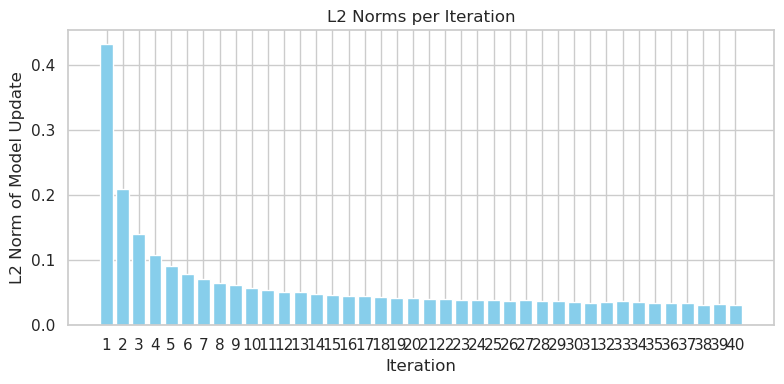

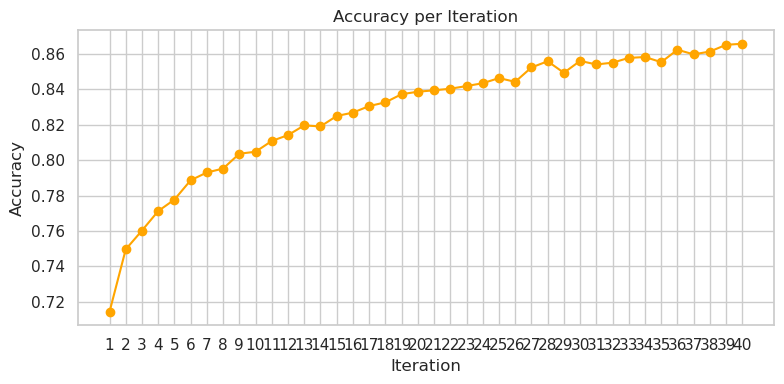

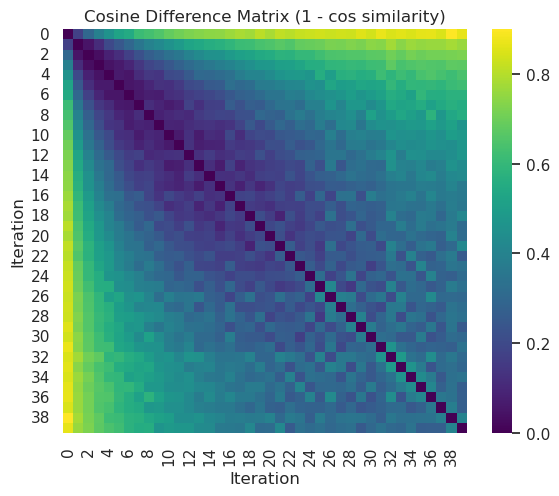

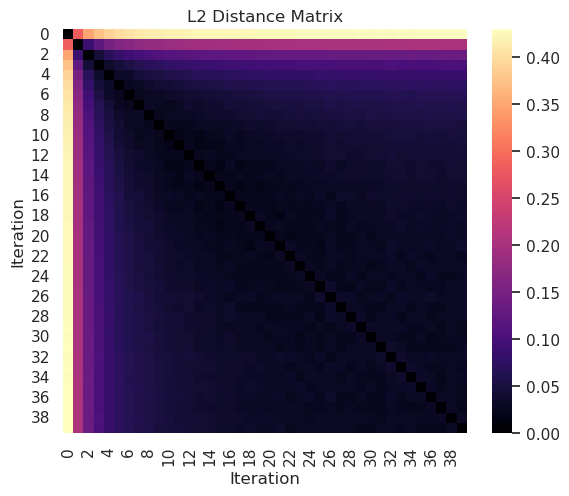

In [18]:
# Ensure seaborn styling
sns.set(style="whitegrid")

# Plot 1: Bar plot of L2 norms
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(l2_norms) + 1), l2_norms, color='skyblue')
plt.xlabel("Iteration")
plt.ylabel("L2 Norm of Model Update")
plt.title("L2 Norms per Iteration")
plt.xticks(range(1, len(l2_norms) + 1))
plt.tight_layout()
plt.show()

# Plot 2: Line plot of Accuracy per Iteration
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(accuracy_list) + 1), accuracy_list, color='orange', marker='o')
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Accuracy per Iteration")
plt.xticks(range(1, len(accuracy_list) + 1))
plt.grid(True)  # Optional: adds grid lines for better readability
plt.tight_layout()
plt.show()


# Convert matrices to numpy
cos_diff_np = cos_diff_matrix.numpy()
l2_diff_np = l2_diff_matrix.numpy()

# Plot 3: Heatmap of cosine differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(cos_diff_np, annot=False, cmap="viridis", square=True)
plt.title("Cosine Difference Matrix (1 - cos similarity)")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()

# Plot 4: Heatmap of L2 differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(l2_diff_np, annot=False, cmap="magma", square=True)
plt.title("L2 Distance Matrix")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()



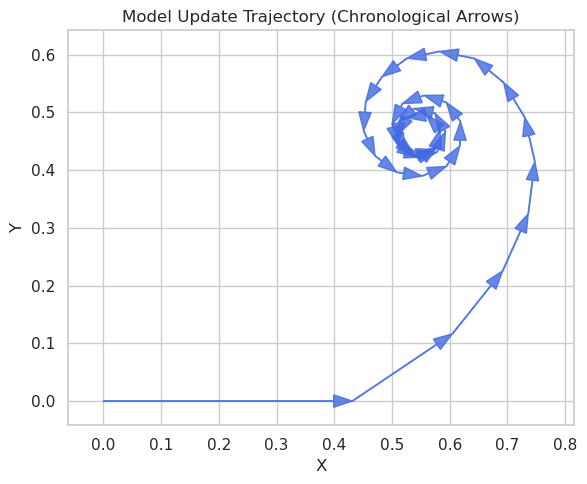

In [19]:
# plot the trajectory of model updates in 2D space

# Step 1: Flatten updates (if not already done)
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]

# Step 2: Get L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Step 3: Compute angles between successive updates
angles = [0.0]  # start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = F.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    # Determine rotation direction using sign of cross product
    sign = torch.sign(torch.dot(u_prev, u_curr))  # crude check
    if sign < 0:
        angle_diff = -angle_diff
    angles.append(angle_diff)

# Step 4: Convert to absolute angles
absolute_angles = [0.0]
for i in range(1, len(angles)):
    absolute_angles.append(absolute_angles[-1] + angles[i])

# Step 5: Compute vector endpoints
x, y = [0], [0]
for i in range(len(l2_norms)):
    dx = l2_norms[i] * np.cos(absolute_angles[i])
    dy = l2_norms[i] * np.sin(absolute_angles[i])
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)

# Step 6: Plot
plt.figure(figsize=(6, 5))
for i in range(len(l2_norms)):
    plt.arrow(x[i], y[i], x[i+1]-x[i], y[i+1]-y[i],
              head_width=0.05*max(l2_norms), length_includes_head=True,
              color='royalblue', alpha=0.8)

plt.title("Model Update Trajectory (Chronological Arrows)")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


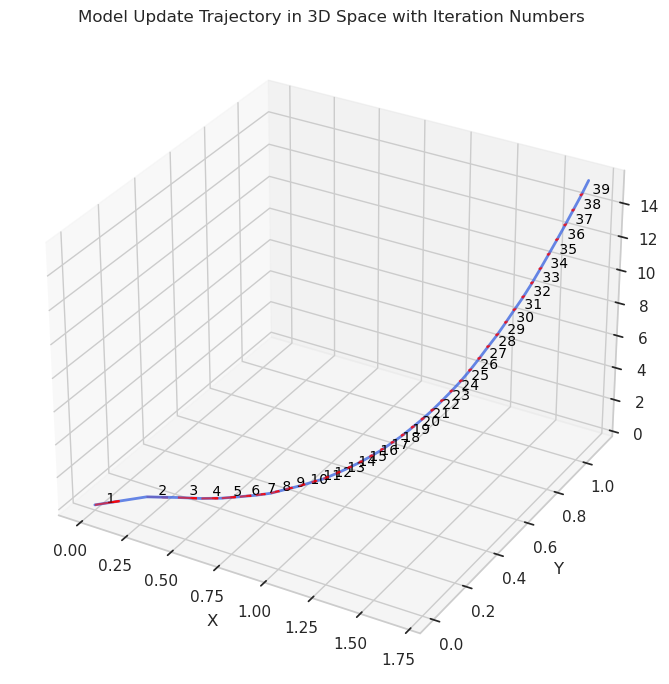

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from mpl_toolkits.mplot3d import Axes3D

# Assuming model_updates is a dictionary or list with flattened model updates
# You would replace the below code with your actual model update data.
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]  # Flatten updates

# Calculate L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Compute angles between consecutive updates (using cosine similarity)
angles = [0.0]  # Start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = torch.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    angles.append(angle_diff)

# Compute 3D coordinates of the trajectory
x, y, z = [0], [0], [0]

# For simplicity, assume updates occur in 3D space
for i in range(1, len(l2_norms)):
    dx = l2_norms[i] * np.cos(angles[i])  # X direction
    dy = l2_norms[i] * np.sin(angles[i])  # Y direction
    dz = i * 0.02  # Slightly separate updates in the Z direction for clarity
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)
    z.append(z[-1] + dz)

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot the 3D trajectory path as a line
ax.plot(x, y, z, color='royalblue', alpha=0.8, linewidth=2)

# Plot arrows for each update
for i in range(len(l2_norms) - 1):
    ax.quiver(x[i], y[i], z[i], x[i+1] - x[i], y[i+1] - y[i], z[i+1] - z[i],
              length=0.1, normalize=True, color='red', alpha=0.6)

    # Add iteration number as a label near the arrows
    ax.text(x[i] + 0.02, y[i] + 0.02, z[i] + 0.02, f" {i+1}", color='black', fontsize=10)

# Labels and title
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title("Model Update Trajectory in 3D Space with Iteration Numbers")

# Display the plot
plt.tight_layout()
plt.show()


# Attack with budget on L2 norm


In [21]:
# copy the trained model0 to modelt
modelt.load_state_dict(model0.state_dict())

# test the modelt
test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(modelt, c_criterion1, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
print(f"modelt accuracy:{accuracy}")

modelt accuracy:0.8657


In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms


# Assuming `modelt` is your pre-trained model on Fashion-MNIST
# Assuming `train_loader` and `val_loader` are DataLoaders for your training and validation data

class NegativeCrossEntropyLoss(nn.Module):
    def __init__(self):
        super(NegativeCrossEntropyLoss, self).__init__()
        self.ce_loss = nn.CrossEntropyLoss()

    def forward(self, outputs, labels):
        return -self.ce_loss(outputs, labels)

def train_one_epoch_with_negative_ce(model, train_loader, device):
    model.train()
    neg_ce_loss = NegativeCrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001)  # Adjust learning rate if needed

    # Save a copy of the original model parameters
    original_state = deepcopy(model.state_dict())

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = neg_ce_loss(outputs, labels)
        
        loss.backward()
        optimizer.step()
    
    # Calculate G_m as the difference between the new and original model parameters
    G_m = {name: model.state_dict()[name] - original_state[name] for name in model.state_dict()}
    model.load_state_dict(original_state)  # Restore original model parameters
    return G_m

def calculate_average_l2_norm(l2_norms):
    return sum(l2_norms) / len(l2_norms)

def calculate_l2_distance(original_weights, attacked_weights):
    """Calculate the L2 distance between two sets of weights."""
    return torch.norm(attacked_weights - original_weights).item()



def apply_attack(model, G_m, average_l2_norm, magnitudes):
    # Calculate total L2 norm of G_m
    total_norm = torch.sqrt(sum((g.float().norm() ** 2 for g in G_m.values())))
    print("G_m norm", total_norm)

    # Compute scaling factor
    multi = average_l2_norm / total_norm
    print("multi", multi)

    # Scale G_m
    normalized_G_m = {name: g.float() * multi for name, g in G_m.items()}
    total_norm_normalized = torch.sqrt(sum((g.norm() ** 2 for g in normalized_G_m.values())))
    print("total_norm_normalized", total_norm_normalized)

    attacked_models = []
    l2_distances = []

    # Flatten original model parameters for distance comparison
    original_params = flatten_model(model.state_dict())

    for magnitude in magnitudes:
        # Create a copy of the original model
        malicious_model = copy.deepcopy(model)

        # Apply attack to parameters and float-type buffers
        with torch.no_grad():
            for name, param in malicious_model.named_parameters():
                if name in normalized_G_m:
                    param.add_(normalized_G_m[name] * magnitude)
            for name, buffer in malicious_model.named_buffers():
                if name in normalized_G_m and torch.is_floating_point(buffer):
                    buffer.add_(normalized_G_m[name] * magnitude)

        # Add the model to the list
        attacked_models.append(malicious_model)

        # Compute L2 distance
        malicious_params = flatten_model(malicious_model.state_dict())
        distance = torch.norm(original_params - malicious_params, p=2)
        l2_distances.append(distance.item())

    return attacked_models, l2_distances



def evaluate_model(model, val_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

def flatten_model(state_dict):
    """Flatten a model's state_dict into a single 1D tensor."""
    return torch.cat([param.flatten() for param in state_dict.values()])

modelt = modelt.to(device)

# Assuming `l2_norms` is the list of L2 norms recorded during benign training
average_l2_norm = calculate_average_l2_norm(l2_norms)
# print(f"Average L2 Norm: {average_l2_norm}")

# Calculate G_m
G_m = train_one_epoch_with_negative_ce(modelt, train_loader, device)
# print("G_m norm", torch.norm(flatten_model(G_m)))

# Define magnitudes
magnitudes = [x * 0.25 for x in range(0, 9)] + list(range(2, 31))

# Apply attack and create malicious models
attacked_models, l2_distances = apply_attack(modelt, G_m, average_l2_norm, magnitudes)
attack_accuracy_list = []



# Evaluate each malicious model
for i, attackeG_model in enumerate(attacked_models):
    print(i)
    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(attackeG_model, c_criterion1, 
                        test_data, server_batch_size=32, class_num=10, attack_method='none',
                        mali_labels=[0,7], device=device)
    
    attack_accuracy_list.append(accuracy*100)
    print(f'Malicious Model {i} with magnitudes {magnitudes[i]}: Accuracy = {accuracy * 100:.2f}')


Average L2 Norm: 0.06256678206846118
G_m norm tensor(5.4410, device='cuda:3')
G_m norm tensor(5.4410, device='cuda:3')
multi tensor(0.0115, device='cuda:3')
total_norm_normalized tensor(0.0626, device='cuda:3')
38
0
Malicious Model 0 with magnitudes 0.0: Accuracy = 86.57
1
Malicious Model 1 with magnitudes 0.25: Accuracy = 86.54
2
Malicious Model 2 with magnitudes 0.5: Accuracy = 86.45
3
Malicious Model 3 with magnitudes 0.75: Accuracy = 86.50
4
Malicious Model 4 with magnitudes 1.0: Accuracy = 86.23
5
Malicious Model 5 with magnitudes 1.25: Accuracy = 85.92
6
Malicious Model 6 with magnitudes 1.5: Accuracy = 85.51
7
Malicious Model 7 with magnitudes 1.75: Accuracy = 85.11
8
Malicious Model 8 with magnitudes 2.0: Accuracy = 84.47
9
Malicious Model 9 with magnitudes 2: Accuracy = 84.47
10
Malicious Model 10 with magnitudes 3: Accuracy = 79.51
11
Malicious Model 11 with magnitudes 4: Accuracy = 71.54
12
Malicious Model 12 with magnitudes 5: Accuracy = 64.11
13
Malicious Model 13 with mag

In [24]:
max_att_index = min(enumerate(attack_accuracy_list), key=lambda x: x[1])[0]
max_attack_l2_dist = l2_distances[max_att_index]

l2_distances

[0.0,
 0.015641698613762856,
 0.03128338232636452,
 0.046925075352191925,
 0.06256677955389023,
 0.07820846140384674,
 0.09385015815496445,
 0.10949186980724335,
 0.12513354420661926,
 0.12513354420661926,
 0.1877003312110901,
 0.2502670884132385,
 0.31283390522003174,
 0.3754006326198578,
 0.437967449426651,
 0.500534176826477,
 0.5631009936332703,
 0.6256678104400635,
 0.6882345676422119,
 0.7508012652397156,
 0.8133680820465088,
 0.8759348392486572,
 0.9385016560554504,
 1.001068353652954,
 1.063635230064392,
 1.1262019872665405,
 1.188768744468689,
 1.251335620880127,
 1.3139022588729858,
 1.3764690160751343,
 1.4390358924865723,
 1.5016025304794312,
 1.5641692876815796,
 1.6267361640930176,
 1.689302921295166,
 1.751869797706604,
 1.814436435699463,
 1.8770033121109009]

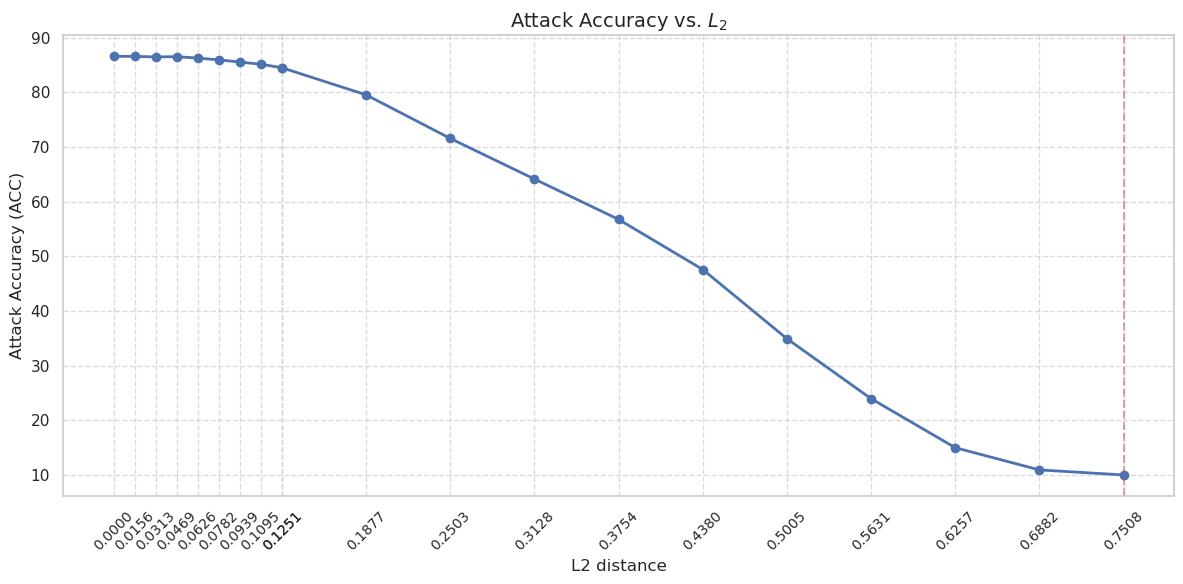

In [25]:
# Create the plot
plt.figure(figsize=(12, 6))
plt.plot(l2_distances[:20], attack_accuracy_list[:20], marker='o', linestyle='-', color='b', linewidth=2)

# Customize the plot
plt.title('Attack Accuracy vs. $L_2$', fontsize=14)
plt.xlabel('L2 distance', fontsize=12)
plt.ylabel('Attack Accuracy (ACC)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Set x-axis ticks: 
# - Show all 0.1 steps from 0.0 to 1.0
# - Then show 1.0 steps from 1.0 to max magnitude
# max_magnitude = max(magnitudes)
# xticks = magnitudes
max_l2 = max(l2_distances)
xticks = l2_distances[:20]
plt.xticks(xticks, fontsize=10)

# Rotate x-axis labels for better readability if many ticks
plt.xticks(rotation=45)

# Add a vertical line at magnitude=1 to mark the transition
plt.axvline(x=max_attack_l2_dist, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [26]:
# Flatten the models
original_flat = flatten_model(model0_sd)
benign_flat = flatten_model(modelt.state_dict())
attacked_flat = flatten_model(attacked_models[max_att_index].state_dict())

models = [original_flat, benign_flat, attacked_flat]
model_names = ["Original", "Benign", "Attacked"]

In [27]:
l2_diff_matrix = torch.zeros(3, 3)
for i in range(3):
    for j in range(3):
        l2_diff_matrix[i, j] = torch.norm(models[i] - models[j]).item()

print("\nL2 Distance Matrix:")
print(l2_diff_matrix)


L2 Distance Matrix:
tensor([[0.0000, 1.9015, 2.1450],
        [1.9015, 0.0000, 0.7508],
        [2.1450, 0.7508, 0.0000]])


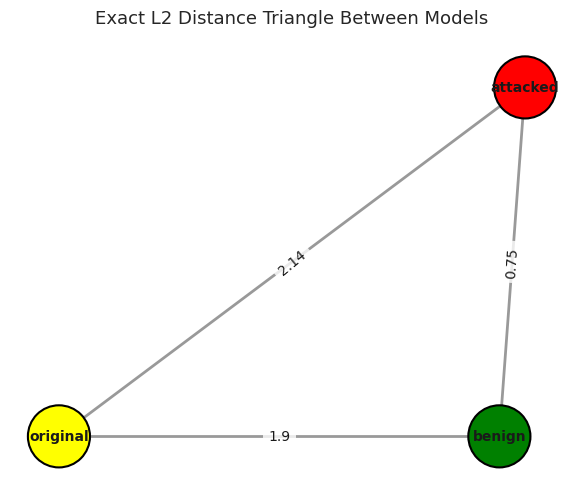

In [28]:
import matplotlib.pyplot as plt
import networkx as nx
import torch
import math

# Distance matrix
l2_matrix = l2_diff_matrix

# Model names
model_names = ['original', 'benign', 'attacked']
model_types = {'original': 'original', 'benign': 'benign', 'attacked': 'attacked'}
color_map = {'original': 'yellow', 'benign': 'green', 'attacked': 'red'}

# Assign positions based on triangle geometry
a = l2_matrix[0, 1].item()  # AB
b = l2_matrix[0, 2].item()  # AC
c = l2_matrix[1, 2].item()  # BC

# Fix A at (0, 0), B at (a, 0), find C
# Use cosine law to get angle at A
cos_CAB = (a**2 + b**2 - c**2) / (2 * a * b)
angle_CAB = math.acos(cos_CAB)

# Coordinates
pos = {
    'original': (0, 0),
    'benign': (a, 0),
    'attacked': (b * math.cos(angle_CAB), b * math.sin(angle_CAB))
}

# Create graph
G = nx.Graph()
for name in model_names:
    G.add_node(name)

# Add edges with L2 distances
for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        G.add_edge(model_names[i], model_names[j], weight=round(l2_matrix[i, j].item(), 2))

# Draw
node_colors = [color_map[model_types[name]] for name in model_names]
plt.figure(figsize=(6, 5))
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color=node_colors, edgecolors='black', linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
nx.draw_networkx_edges(G, pos, width=2, edge_color='gray', alpha=0.8)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels, font_size=10,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8)
)

plt.title("Exact L2 Distance Triangle Between Models", pad=20, fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.show()


In [30]:
# for each layer we test the sensitivity in regards of the attack

def apply_attack_to_specific_layer(model, G_m, l2_budget, layer_name):
    # Calculate the total L2 norm of the gradient update for normalization
    total_norm = torch.sqrt(sum((g_m.norm() ** 2 for g_m in G_m.values())))
    normalized_G_m = {name: g_m * (l2_budget / total_norm) for name, g_m in G_m.items()}

    new_model = deepcopy(model)
    for name, param in new_model.named_parameters():
        if name == layer_name:
            # Calculate the current L2 norm of the specific layer's update
            current_layer_norm = normalized_G_m[name].norm()
            
            # Calculate the magnitude needed to achieve the specified L2 budget
            if current_layer_norm != 0:
                magnitude = l2_budget / current_layer_norm
            else:
                magnitude = 0  # Avoid division by zero
            
            # Apply the calculated magnitude to achieve the L2 budget
            param.data += magnitude * normalized_G_m[name]

    return new_model


def apply_attack_to_all_layers(model, G_m, l2_budget):
    # Convert all gradients to float and compute total L2 norm
    total_norm = torch.sqrt(sum((g_m.float().norm() ** 2 for g_m in G_m.values())))
    
    # Avoid division by zero
    if total_norm == 0:
        return model
    
    # Compute scaling factor
    scale = min(1.0, l2_budget / total_norm)
    print("scale", scale)
    
    # Apply scaled attack to each layer
    attacked_model = copy.deepcopy(model)
    with torch.no_grad():
        for name, param in attacked_model.named_parameters():
            if name in G_m:
                # Ensure both parameter and gradient are float
                param.data += scale * G_m[name].float().to(param.device)
    
    return attacked_model


def evaluate_and_record_sensitivities(model, G_m, max_l2, num_records, test_data, device):
    # Convert gradients to float upfront
    G_m = {name: g_m.float() for name, g_m in G_m.items()}
    
    layer_names = [name for name, _ in model.named_parameters()]
    # Create a sequence of L2 distances
    l2_dists = np.linspace(0, max_l2, num_records)
    results_matrix = np.zeros((len(layer_names), len(l2_dists)))
    print("layer_names", layer_names)
    
    for layer_index, layer_name in enumerate(layer_names):
        print(f"Evaluating layer: {layer_name}")
        for idx, l2_budget in enumerate(l2_dists):
            attacked_model = apply_attack_to_specific_layer(model, G_m, l2_budget, layer_name)
            test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(
                attacked_model, c_criterion1, test_data, server_batch_size=32, class_num=10,
                attack_method='none', mali_labels=[0, 7], device=device
            )
            results_matrix[layer_index, idx] = accuracy
            print(f"Layer: {layer_name}, L2 Budget: {l2_budget:.2f}, Accuracy: {accuracy:.4f}")

    return results_matrix, layer_names, l2_dists


def evaluate_attack_on_all_layers(model, G_m, max_l2, num_records, test_data, device):
    # Create a sequence of L2 distances
    l2_dists = np.linspace(0, max_l2, num_records)
    results_list = []
    
    # Convert all gradients in G_m to float upfront
    G_m = {k: v.float() for k, v in G_m.items()}
    
    for l2_budget in l2_dists:
        print(f"Evaluating attack with total L2 budget: {l2_budget}")
        attacked_model = apply_attack_to_all_layers(model, G_m, l2_budget)
        test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(
            attacked_model, c_criterion1, test_data, server_batch_size=32, class_num=10,
            attack_method='none', mali_labels=[0, 7], device=device
        )
        results_list.append(accuracy)
        print(f"L2 Budget: {l2_budget}, Accuracy: {accuracy}")

    return np.array(results_list), l2_dists



def plot_sensitivity_matrix(results_matrix, layer_names, L2_dists):
    plt.figure(figsize=(12, 6))
    im = plt.imshow(results_matrix, aspect='auto', cmap='viridis', origin='lower')

    # Get min and max values from the matrix
    vmin = results_matrix.min()
    vmax = results_matrix.max()

    # Create colorbar with ticks at 0.1 intervals between min and max
    ticks = np.arange(vmin, vmax + 0.1, 0.1)
    ticks = np.clip(ticks, vmin, vmax)  # Ensure ticks don't go beyond min and max

    cbar = plt.colorbar(im, ticks=ticks)
    cbar.ax.set_yticklabels([f"{tick:.2f}" for tick in ticks])
    cbar.set_label('Accuracy')

    plt.xlabel('L2 Distance')
    plt.ylabel('Layer Index')

    # Tick positions: every 2nd plus the last if not already included
    tick_indices = list(np.arange(0, len(L2_dists), 1))
    if (len(L2_dists) - 1) not in tick_indices:
        tick_indices.append(len(L2_dists) - 1)

    formatted_xticks = [f"{L2_dists[i]:.4f}" for i in tick_indices]
    plt.xticks(ticks=tick_indices, labels=formatted_xticks, rotation=45)

    plt.yticks(ticks=np.arange(len(layer_names)), labels=layer_names)
    plt.gca().invert_yaxis()

    plt.title('Sensitivity Analysis of Layers to Attack')
    plt.tight_layout()
    plt.show()


In [31]:
# Evaluate and record sensitivities
results_matrix, layer_names, l2_distances = evaluate_and_record_sensitivities(
    modelt, G_m, max_attack_l2_dist, 10, test_data, device
)

layer_names ['features.0.weight', 'features.0.bias', 'features.1.weight', 'features.1.bias', 'features.4.weight', 'features.4.bias', 'features.5.weight', 'features.5.bias', 'features.8.weight', 'features.8.bias', 'features.9.weight', 'features.9.bias', 'classifier.weight', 'classifier.bias']
Evaluating layer: features.0.weight
Layer: features.0.weight, L2 Budget: 0.00, Accuracy: 0.8657
Layer: features.0.weight, L2 Budget: 0.04, Accuracy: 0.8661
Layer: features.0.weight, L2 Budget: 0.08, Accuracy: 0.8657
Layer: features.0.weight, L2 Budget: 0.12, Accuracy: 0.8658
Layer: features.0.weight, L2 Budget: 0.16, Accuracy: 0.8652
Layer: features.0.weight, L2 Budget: 0.20, Accuracy: 0.8640
Layer: features.0.weight, L2 Budget: 0.24, Accuracy: 0.8627
Layer: features.0.weight, L2 Budget: 0.28, Accuracy: 0.8617
Layer: features.0.weight, L2 Budget: 0.32, Accuracy: 0.8603
Layer: features.0.weight, L2 Budget: 0.36, Accuracy: 0.8597
Layer: features.0.weight, L2 Budget: 0.40, Accuracy: 0.8576
Layer: feat

In [32]:
max_attack_l2_dist

0.7508012652397156

In [33]:
results_list_all, l2_dists_all = evaluate_attack_on_all_layers(modelt, G_m, max_attack_l2_dist, 20, test_data, device)

Evaluating attack with total L2 budget: 0.0
scale tensor(0., device='cuda:3')
L2 Budget: 0.0, Accuracy: 0.8657
Evaluating attack with total L2 budget: 0.03951585606524819
scale tensor(0.0073, device='cuda:3')
L2 Budget: 0.03951585606524819, Accuracy: 0.8653
Evaluating attack with total L2 budget: 0.07903171213049638
scale tensor(0.0145, device='cuda:3')
L2 Budget: 0.07903171213049638, Accuracy: 0.8592
Evaluating attack with total L2 budget: 0.11854756819574458
scale tensor(0.0218, device='cuda:3')
L2 Budget: 0.11854756819574458, Accuracy: 0.8479
Evaluating attack with total L2 budget: 0.15806342426099276
scale tensor(0.0291, device='cuda:3')
L2 Budget: 0.15806342426099276, Accuracy: 0.8241
Evaluating attack with total L2 budget: 0.19757928032624095
scale tensor(0.0363, device='cuda:3')
L2 Budget: 0.19757928032624095, Accuracy: 0.7833
Evaluating attack with total L2 budget: 0.23709513639148916
scale tensor(0.0436, device='cuda:3')
L2 Budget: 0.23709513639148916, Accuracy: 0.7324
Evaluat

In [34]:
results_list_all, l2_dists_all

(array([0.8657, 0.8653, 0.8592, 0.8479, 0.8241, 0.7833, 0.7324, 0.6857,
        0.6357, 0.5894, 0.5445, 0.4828, 0.4029, 0.323 , 0.2526, 0.1938,
        0.144 , 0.1158, 0.1027, 0.1   ]),
 array([0.        , 0.03951586, 0.07903171, 0.11854757, 0.15806342,
        0.19757928, 0.23709514, 0.27661099, 0.31612685, 0.3556427 ,
        0.39515856, 0.43467442, 0.47419027, 0.51370613, 0.55322198,
        0.59273784, 0.6322537 , 0.67176955, 0.71128541, 0.75080127]))

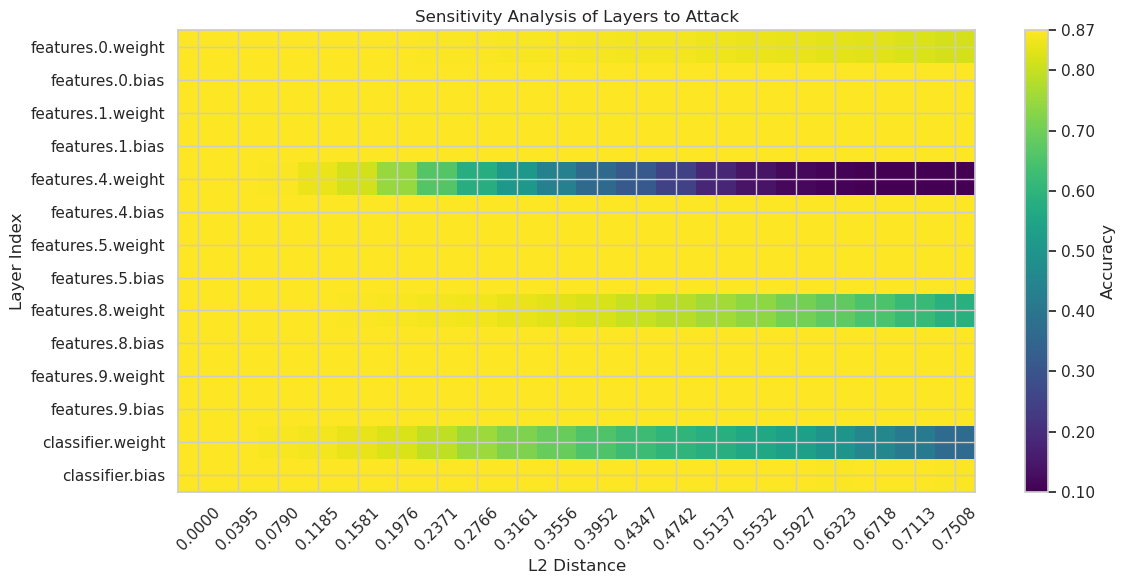

In [35]:
# Plot the sensitivity matrix
plot_sensitivity_matrix(results_matrix, layer_names, l2_dists_all)

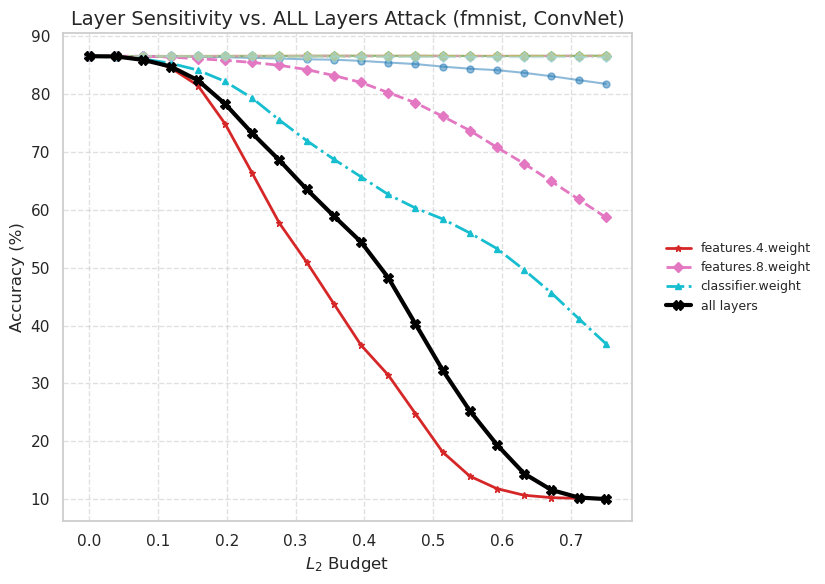

In [36]:
import itertools

def plot_sensitivity_lines_2(results_matrix, layer_names, L2_dists, results_list_all=None):
    import matplotlib.pyplot as plt
    import numpy as np
    import itertools

    plt.figure(figsize=(10, 6))  # Slightly larger figure to accommodate legend

    # Colors and styles
    line_styles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'D', '*']
    colors = plt.cm.tab20(np.linspace(0, 1, len(layer_names)))
    style_combinations = list(itertools.product(line_styles, markers))

    # Determine dynamic threshold: 80% of the global max accuracy
    max_accuracy = results_matrix.max() * 100  # in percentage
    threshold = 0.9 * max_accuracy

    for idx, (layer_name, color) in enumerate(zip(layer_names, colors)):
        acc_curve = results_matrix[idx] * 100  # Convert to percentage
        min_acc = acc_curve.min()
        line_style, marker = style_combinations[idx % len(style_combinations)]

        if min_acc < threshold:
            label = layer_name
            linewidth = 2
            alpha = 1.0
        else:
            label = None
            linewidth = 1.5
            alpha = 0.5

        plt.plot(
            L2_dists, acc_curve, label=label,
            linestyle=line_style, marker=marker, color=color,
            linewidth=linewidth, markersize=5, alpha=alpha
        )

    # Plot "ALL" line
    if results_list_all is not None:
        plt.plot(
            L2_dists, results_list_all * 100, label="all layers",  # Convert to percentage
            color='black', linestyle='-', linewidth=3,
            marker='X', markersize=7
        )

    # Remove duplicate labels and place legend outside
    handles, labels = plt.gca().get_legend_handles_labels()
    unique = dict(zip(labels, handles))  # Remove duplicates
    
    # Place legend outside to the right of the plot
    plt.legend(
        unique.values(), 
        unique.keys(), 
        loc='center left', 
        bbox_to_anchor=(1.04, 0.5), 
        fontsize=9,
        frameon=False
    )

    plt.xlabel('$L_2$ Budget', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Layer Sensitivity vs. ALL Layers Attack ({dataset}, {model_name})', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for legend
    plt.show()



plot_sensitivity_lines_2(results_matrix, layer_names, l2_dists_all, results_list_all)